# Material de aula - FACENS - Aprendizado de Máquina


## Scikit Learn - Laboratório 02

In [1]:
#CÉLULA SCIKIT-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

# 2 - Clusterização de dados com k-means

## 2.1 Importe o pacote k-means da biblioteca

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler


## Descrição dos dados:

Estes dados são o resultado de uma análise química de vinhos produzidos na mesma região da Itália, porém derivados de 3 cultivares distintos. As análises determinaram as quantidades de 13 constituentes encontrados em cada um dos 3 tipos de vinhos.

Os atributos são:

* Alcohol 
* Malic acid 
* Ash 
* Alcalinity of ash 
* Magnesium 
* Total phenols 
* Flavanoids 
* Nonflavanoid phenols 
* Proanthocyanins 
* Color intensity 
* Hue 
* OD280/OD315 of diluted wines 
* Proline

## 2.2 - Análise Exploratória: faça a carga do arquivo Wine.csv, analise as colunas, as informações e o formato do dataset

In [8]:
dfDataFile = pd.read_csv('Wine.csv')
dfDataFile.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [17]:
dfDataFile.columns
dfDataFile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
Alcohol                 178 non-null float64
Malic_Acid              178 non-null float64
Ash                     178 non-null float64
Ash_Alcanity            178 non-null float64
Magnesium               178 non-null int64
Total_Phenols           178 non-null float64
Flavanoids              178 non-null float64
Nonflavanoid_Phenols    178 non-null float64
Proanthocyanins         178 non-null float64
Color_Intensity         178 non-null float64
Hue                     178 non-null float64
OD280                   178 non-null float64
Proline                 178 non-null int64
Customer_Segment        178 non-null int64
dtypes: float64(11), int64(3)
memory usage: 19.5 KB


## 2.3  Remova a coluna 'Customer_Segment ' e aplique a normalização dos dados usando o MaxMinScaler

In [35]:
dfAux = dfDataFile.drop(['Customer_Segment'],axis=1)
dfAux.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [37]:
import seaborn as sns

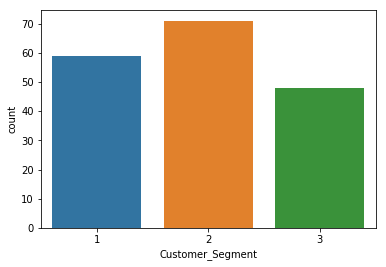

In [40]:
sns.countplot(dfDataFile['Customer_Segment'])

In [15]:
scaler = MinMaxScaler()
scalerresult = scaler.fit(dfAux.values)
scalerresult

MinMaxScaler(copy=True, feature_range=(0, 1))

In [18]:
WineArrayNorm = scalerresult.transform(dfAux)
WineArrayNorm

array([[0.84210526, 0.1916996 , 0.57219251, ..., 0.45528455, 0.97069597,
        0.56134094],
       [0.57105263, 0.2055336 , 0.4171123 , ..., 0.46341463, 0.78021978,
        0.55064194],
       [0.56052632, 0.3201581 , 0.70053476, ..., 0.44715447, 0.6959707 ,
        0.64693295],
       ...,
       [0.58947368, 0.69960474, 0.48128342, ..., 0.08943089, 0.10622711,
        0.39728959],
       [0.56315789, 0.36561265, 0.54010695, ..., 0.09756098, 0.12820513,
        0.40085592],
       [0.81578947, 0.66403162, 0.73796791, ..., 0.10569106, 0.12087912,
        0.20114123]])

## 2.4 - Aplique o algoritmo k-means para separar os dados em 3 clusters

In [20]:
km = KMeans(n_clusters=3,random_state=0)

In [23]:
clusters = km.fit(WineArrayNorm)
clusters

KMeans(algorithm='auto', copy_x=True, init='k-means++', max_iter=300,
    n_clusters=3, n_init=10, n_jobs=1, precompute_distances='auto',
    random_state=0, tol=0.0001, verbose=0)

## 2.5 - Verifique os identificadores de clusters na variável 'labels_'

In [24]:
clusters.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 1, 2, 1, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1])

## 2.6 - Verifique as coordenadas dos centros dos clusters na variável 'cluster_centers_'

In [26]:
clusters.cluster_centers_

array([[0.70565142, 0.24842869, 0.58490401, 0.3444313 , 0.41072701,
        0.64211419, 0.55467939, 0.30034024, 0.47727155, 0.35534046,
        0.47780888, 0.69038612, 0.59389397],
       [0.544689  , 0.47844053, 0.56013612, 0.53833177, 0.31146245,
        0.24476489, 0.10713464, 0.61852487, 0.22827646, 0.4826404 ,
        0.19254989, 0.16090576, 0.24739982],
       [0.31137521, 0.23689915, 0.47291703, 0.49991686, 0.2477209 ,
        0.45305895, 0.38240098, 0.4117468 , 0.39742546, 0.14773478,
        0.47351167, 0.58897554, 0.15640099]])

## 2.7 - Verifique a dispersão intra-cluster

In [27]:
#calcula e soma os intra clusters
clusters.inertia_

48.960517136676486

## 2.8 - Calcule a dispersão intra-cluster para o numero de clusters entre 1 e 30 e plote o resultado

In [43]:
w=[]
for nCluster in range(1,30):
    km = KMeans(n_clusters=nCluster,random_state=0)
    clusters = km.fit(WineArrayNorm)
    w.append(clusters.inertia_)

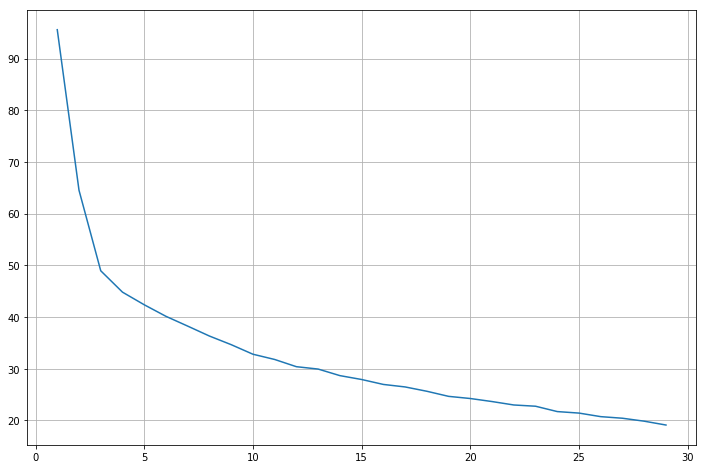

In [45]:
plt.figure(figsize=(12,8))
plt.grid()
plt.plot(range(1,30),w)
#soma da distenca intra cluster

## 2.9 - Utilizando as funções programadas para o k-means abaixo, faça o mesmo gráfico dos clusters do dataset

In [ ]:
#CÉLULA KMEANS-LIB-02
def euclidean_distance(v1, v2) :
    '''
    Esta função recebe 2 arrays (do tipo np.array) e retorna a distância euclidiana entre eles
    
    Parâmetros
    ----------
    v1 -> vetor de coordenadas do primeiro ponto
    v2 -> vetor de coordenadas do segundo ponto
    
    Retorno
    -------
    Distância entre os dois pontos    
    '''
    return np.sqrt( sum((v1 - v2)**2) )

In [ ]:
#CÉLULA KMEANS-LIB-03
def kmeans(vData, nClusters) :
    '''
    Este método calcula os centroides dos clusters de um conjunto de dados a partir do algoritmo k-means
    
    Parâmetros
    ----------
    vData -> vetor de coordenadas N-Dimensionais dos dados. Cada posição do array deve ser uma lista de coordenadas
        
    Retorno
    -------
    Uma tupla (vPoints, vClusterCenters), onde:
    
    vPoints -> é um Array contendo a lista de pontos observados, onde cada posição do array corresponde a um clusterId. 
    Cada ponto do array de retorno é definido como um dicionário com a seguinte estrutura:
        {
         'pointCoord'  : coordenadas do ponto, 
         'centerCoord' : coordenadas de seu centroide, 
         'clusterId'   : identificador do cluster
        }
        
    vClusterCenters -> é uma lista contendo as coordenadas de cada centróide, ordenadas de acordo com o índice 'clusterId'
    '''

    #Inicialização sequencial dos centroides
    #vClusterCenters = [vData[i] for i in range(0, nClusters)]    
    
    #Inicialização usando kmeans++
    vClusterCenters = [vData[0]]
    for k in range(1, nClusters):
        D2 = np.array([min([np.inner(c-x,c-x) for c in vClusterCenters]) for x in vData])#produto interno entre x e distancia c
        probs = D2/D2.sum()
        cumprobs = probs.cumsum()
        r = np.random.rand()
        for j,p in enumerate(cumprobs):
            if r < p:
                i = j
                break
        vClusterCenters.append(vData[i])
        
    vPoints = [{'point':point, 'clusterId' : -1, 'centerCoord' : point*0} for point in vData]
    
    clusterIsChanging = True
    while(clusterIsChanging == True) :
    
        clusterIsChanging = False

        for dataPoint in vPoints :
            #Calcula a distancia entre o ponto 'dataPoint' e todos os centroides
            vDistances = [ euclidean_distance(dataPoint['point'], center) for center in vClusterCenters ]
            #Define a menor distância
            clusterIndex = np.argmin(vDistances)

            #Verifica se houve mudança de atribuição e ativa o flag em caso afirmativo            
            if( dataPoint['clusterId'] != clusterIndex ) :
                dataPoint['clusterId']  = clusterIndex
                clusterIsChanging = True

        #Após a redistribuição dos pontos, recalcula os centroides
        for clusterIndex, clusterCenter in enumerate(vClusterCenters) :
            #Realiza o agrupamento dos pontos de um dado cluster
            clusterData = [ point['point'] for point in vPoints if point['clusterId'] == clusterIndex ]
            #atualiza centroide do cluster indicado pelo clusterIndex
            vClusterCenters[clusterIndex] = np.mean(clusterData, axis=0) 

    #Atualiza as coordenadas dos centroides calculados pelo algoritmo   
    for dataPoint in vPoints :
        dataPoint['centerCoord'] = vClusterCenters[dataPoint['clusterId']]

    return (vPoints, vClusterCenters)

In [ ]:
#CÉLULA KMEANS-LIB-04
def cluster_distortion(vDataPoints, nClusters) :
    '''
    Esta função calcula a distorção intra-cluster
    
    Parâmetros
    ----------
    vDataPoints -> array contendo os pontos (dados observados). Cada ponto é definido como um dicionário com a seguinte estrutura
        {'pointCoord' : coordenadas do ponto, 'centerCoord' : coordenadas de seu centroide, 'clusterId' : identificador do cluster}
    
    nClusters   -> quantidade de clusters utilizados
    
    
    Retorno
    -------
    
    Um array contendo a distorção intra-cluster de todos os clusters, onde cada posição do array corresponde ao clusterId    
    '''
    vClusterDist = []
    
    for i in range(nClusters):
        #Realiza o agrupamento dos pontos de um dado cluster
        vClusterPoints = [point for point in vDataPoints if point['clusterId']==i]
        
        #Calcula a soma das distâncias (elevadas ao quadrado) entre um cada ponto e o centro de seu respectivo cluster. 
        distance = sum([euclidean_distance(point['point'], point['centerCoord'])**2 for point in vClusterPoints])
        vClusterDist.append(distance)
        
    return vClusterDist

### 2.9.1 - Calcule a clusterização para k=3

In [ ]:
nCluster = 3
clusterData,_ = kmeans(WineArrayNorm,nCluster)

nClusters = []
for item in clusterData

### 2.9.2 - Calcule a dispersão intra-cluster para k=3

In [ ]:
cd clusters_distorion

### 2.9.3 - Calcule a dispersão intra-cluster para o numero de clusters entre 1 e 30 e plote o resultado

### 2.9.4 - Calcule a dispersão inter-cluster para o numero de clusters entre 1 e 30 e plote o resultado

## 2.10 - Utilizando o seaborn, verifique os rótulos 'Customer_Segment'

## 2.11 - Ajuste os labels para ficarem iguais ao resultado do k-means

## 2.12 - Importe o pacote de matriz de confusão

### 2.12.1 - Exemplo de matriz de confusão

 ### 2.12.2 - Avalie a clusterização para k=3

### 2.12.3 - Plote o relatório de classificação da matriz de confusão